In [30]:
import numpy as np
import pandas as pd
import pyagrum as gum
import pyagrum.lib.notebook as gnb
import pyagrum.lib.dynamicBN as gdyn

from cross_impact.model import build_network, UncertaintyFactor, CrossImpactNetwork
from cross_impact.pyagrum_import import marginals_and_joint_from_pyagrum
from cross_impact.pyagrum_export import graft_onto_pyagrum
from cross_impact.model import cross_impacts_from_joint

In [31]:
# The uncertainty factors, or dnb nodes
factortuples = [
    ("HHA", 3, ()),  # 0
    ("GER", 2, ()),  # 1
    ("OMA", 2, ()),  # 2

    ("PIS0", 4, ()), # 3
    ("PIH0", 5, (0,3,)), # 4
    ("LYS0", 4, (3,4,)), # 5
    ("LYH0", 7, (0,3,4,5,)), # 6
    ("AST0", 3, (1,2,4,6,)), # 7
    ("KUO0", 2, (3,4,5,6,)), # 8

    ("PISt", 4, (3,4,5,6,)), # 9
    ("PIHt", 5, (1,2,4,6,8,)), # 10
    ("LYSt", 4, (1,2,5,6,8,9,)), # 11
    ("LYHt", 7, (1,2,6,8,9,10,)), # 12
    ("ASTt", 3, (9,11,)), # 13
    ("KUOt", 2, (9,10,11,12,)), # 14
]
factors = [UncertaintyFactor(factor[0], factor[1], factor[2]) for factor in factortuples]

In [32]:
# marginals for each uncertainty factor
hha_mar = np.array([0.3, 0.4, 0.3])
ger_mar = np.array([0.7, 0.3])
oma_mar = np.array([0.5, 0.5])
pis_mar = np.array([0.0993, 0.388, 0.4343, 0.0784])
pih_mar = np.array([0.7467, 0.042, 0.14, 0.0663, 0.005])
lys_mar = np.array([0.9637, 0.0099, 0.0185, 0.0079])
lyh_mar = np.array([0.950, 0.031, 0.005, 0.01, 0.001, 0.003, 0])
ast_mar = np.array([0.5, 0.2, 0.3])
kuo_mar = np.array([0.00015, 1-0.00015])

In [10]:
cross_impacts = {}
for fi, factor in enumerate(factortuples):
    for parent_index in factor[2]:
        factor_dim = factor[1]
        parent_dim = factortuples[parent_index][1]
        cross_impacts[(parent_index, fi)] = np.zeros((parent_dim, factor_dim))

for ci in cross_impacts:
    print(f"{ci}: ----- \n {cross_impacts[ci]} \n")

[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
[[0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]]
[[0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]]
[[0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]]
[[0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]]
[[0. 0. 0.]
 [0. 0. 0.]]
[[0. 0. 0.]
 [0. 0. 0.]]
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
[[0

In [34]:
network = CrossImpactNetwork(
    factors=factors,
    marginals=[
        hha_mar,
        ger_mar,
        oma_mar,
        
        pis_mar,
        pih_mar,
        lys_mar,
        lyh_mar,
        ast_mar,
        kuo_mar,
        
        pis_mar,
        pih_mar,
        lys_mar,
        lyh_mar,
        ast_mar,
        kuo_mar,
    ],
    cross_impacts=cross_impacts,
)
built = build_network(network, mode="independent", initial_joint=None)

/home/vili/bayes-learning/cross_impact/fitting.py:74: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  problem.solve()


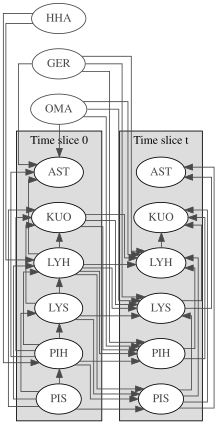

In [35]:
from cross_impact.pyagrum_export import to_pyagrum

bn = to_pyagrum(built)
gdyn.showTimeSlices(bn)

# HUOMIO! Lisää noodi, joka käsittelee kuolleen erikseen! eli siis kaikki tuo on ehdollistettu sillä, että henkilö on elossa.

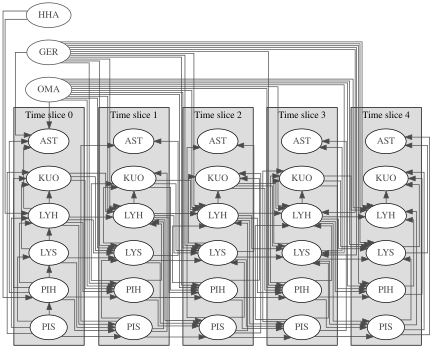

In [36]:
T = 5
dbn = gdyn.unroll2TBN(bn, T)
gdyn.showTimeSlices(dbn)

In [38]:
ie = gum.LazyPropagation(dbn)
for i in range(4):
    ie.setEvidence({"PIS3": i})
    gnb.sideBySide(ie.posterior("PIS3"), ie.posterior("PIS4"), ie.posterior("KUO3"))